In [1]:

# ==========================================
# CNN: Handwritten Digit Recognition
# Dataset: MNIST
# Framework: TensorFlow / Keras
# ==========================================

# Step 1: Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


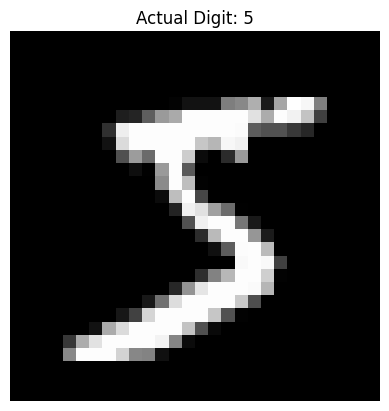

Training shape after preprocessing: (60000, 28, 28, 1)
Testing shape after preprocessing: (10000, 28, 28, 1)


In [2]:
# Step 2: Load Dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

# Step 3: Display a Sample Image
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis("off")
plt.show()

# Step 4: Normalize the Images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Step 5: Add Channel Dimension
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training shape after preprocessing:", X_train.shape)
print("Testing shape after preprocessing:", X_test.shape)



In [3]:
# Step 6: Build the CNN Model
model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

# Step 7: Display Model Architecture
model.summary()

# Step 8: Compile the Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Step 9: Train the Model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Step 10: Evaluate the Model
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Step 11: Predict the First 10 Test Images
probabilities = model.predict(X_test[:10], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

print("\nPredicted Labels:", predicted_labels)
print("Actual Labels:   ", y_test[:10])



Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 54ms/step - accuracy: 0.9348 - loss: 0.2084 - val_accuracy: 0.9862 - val_loss: 0.0505
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9790 - loss: 0.0684 - val_accuracy: 0.9870 - val_loss: 0.0427
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 50ms/step - accuracy: 0.9847 - loss: 0.0491 - val_accuracy: 0.9907 - val_loss: 0.0348
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9879 - loss: 0.0395 - val_accuracy: 0.9928 - val_loss: 0.0283
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9901 - loss: 0.0316 - val_accuracy: 0.9920 - val_loss: 0.0309

Test Loss: 0.027
Test Accuracy: 99.06 %

Predicted Labels: [7 2 1 0 4 1 4 9 5 9]
Actual Labels:    [7 2 1 0 4 1 4 9 5 9]


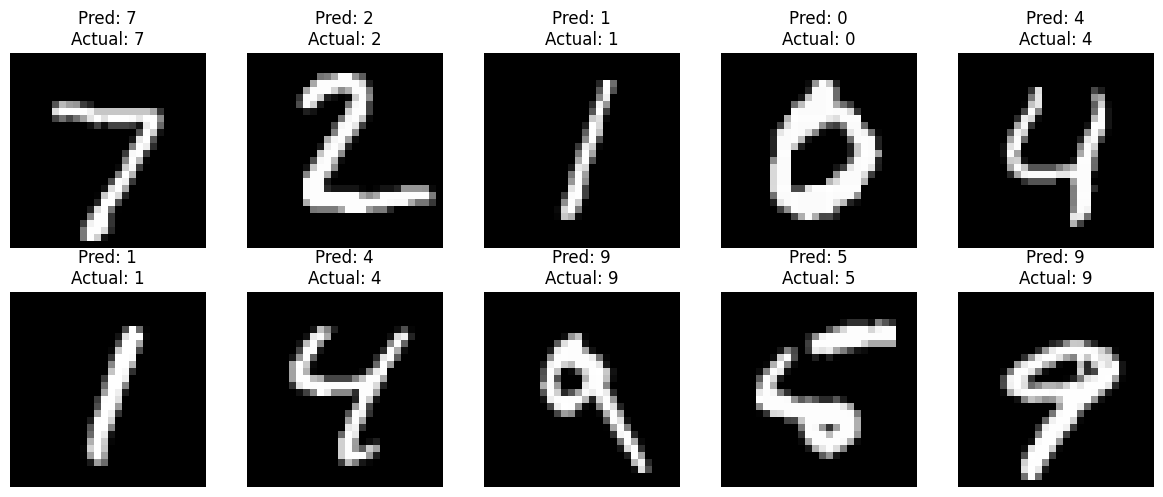

In [5]:
# Step 12: Display Predictions
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")

    predicted_digit = predicted_labels[i]
    actual_digit = y_test[i]

    plt.title(
        f"Pred: {predicted_digit}\nActual: {actual_digit}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()



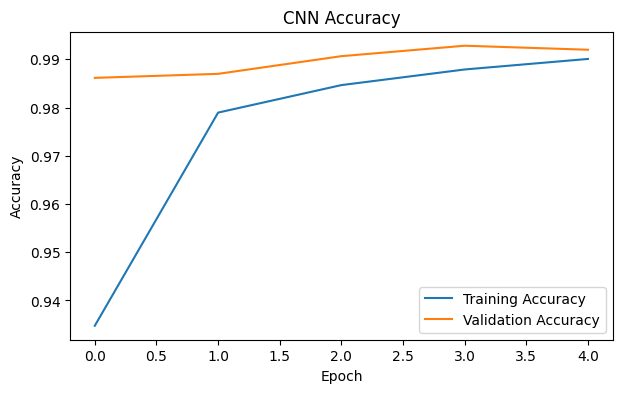

In [6]:
# Step 13: Plot Training and Validation Accuracy
plt.figure(figsize=(7, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()



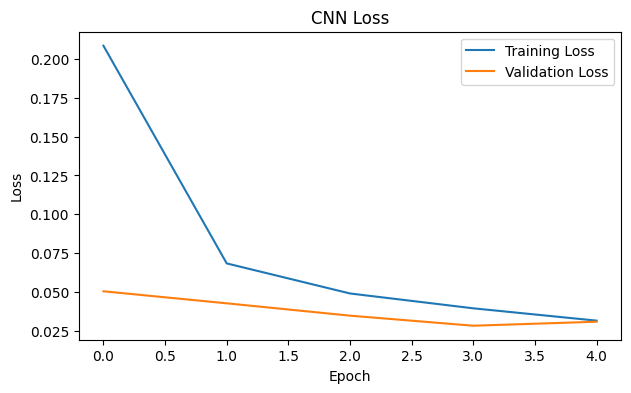

In [7]:
# Step 14: Plot Training and Validation Loss
plt.figure(figsize=(7, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.show()
